# RouteRanker – Milestone 1: Chennai MTC Data Collection & Inspection

**Project:** AI-Powered Public Transit Route Optimization  
**City:** Chennai, Tamil Nadu  
**Milestone 1 focus:** Data collection, data understanding, quality inspection and initial route-level feature engineering.

## Objective
This notebook loads the Chennai Metropolitan Transport Corporation (MTC) General Transit Feed Specification (GTFS) data, checks the structure and quality of the main tables, and creates an initial route-level summary for later analysis.

## Dataset and scope
Source repository: https://github.com/ungalsoththu/ChennaiGTFS  
Feed used: MTC buses (`mtc-gtfs.zip`)

GTFS is schedule and network data. It describes routes, trips, stops and scheduled stop times. **It does not contain actual passenger boarding counts by itself.** Therefore, this notebook does not claim to measure real passenger demand or overcrowding.

## Expected input files
- `routes.txt`
- `trips.txt`
- `stops.txt`
- `stop_times.txt`

The download cell below obtains the MTC feed ZIP and extracts it. If the source URL changes, download `mtc-gtfs.zip` from the source repository and place it in the `data/raw/` folder.


## 1. Import required libraries

We use pandas for tabular data processing, NumPy for numerical operations, Matplotlib and Seaborn for basic visual inspection, and pathlib/zipfile for file handling.

In [2]:
import sys
import zipfile
import urllib.request
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 100)

print("Python:", sys.version.split()[0])
print("Pandas:", pd.__version__)
print("NumPy:", np.__version__)

Python: 3.13.18
Pandas: 2.2.3
NumPy: 2.4.6


## 2. Download and extract the Chennai MTC GTFS dataset

The dataset is downloaded from the source repository into `data/raw/`. The ZIP is extracted into `data/raw/mtc_gtfs/`. If you already have the ZIP, set `DOWNLOAD_DATA = False` and make sure the ZIP is inside `data/raw/`.

In [3]:
PROJECT_DIR = Path.cwd()
RAW_DIR = PROJECT_DIR / "data" / "raw"
GTFS_DIR = RAW_DIR / "mtc_gtfs"
ZIP_PATH = RAW_DIR / "mtc-gtfs.zip"

RAW_DIR.mkdir(parents=True, exist_ok=True)
GTFS_DIR.mkdir(parents=True, exist_ok=True)

DOWNLOAD_DATA = True
DATA_URL = "https://github.com/ungalsoththu/ChennaiGTFS/raw/refs/heads/main/data/mtc-gtfs.zip"

if DOWNLOAD_DATA and not ZIP_PATH.exists():
    print("Downloading Chennai MTC GTFS data...")
    urllib.request.urlretrieve(DATA_URL, ZIP_PATH)
    print("Download complete:", ZIP_PATH)

if ZIP_PATH.exists():
    with zipfile.ZipFile(ZIP_PATH, "r") as zf:
        zf.extractall(GTFS_DIR)
    print("Extracted dataset to:", GTFS_DIR)
else:
    print("ZIP file not found. Place mtc-gtfs.zip in data/raw/ and run this cell again.")

# Find the required GTFS files, even if the ZIP contains a nested folder.
def find_gtfs_file(filename):
    matches = list(GTFS_DIR.rglob(filename))
    return matches[0] if matches else None

gtfs_paths = {
    name: find_gtfs_file(name)
    for name in ["routes.txt", "trips.txt", "stops.txt", "stop_times.txt"]
}
for name, path in gtfs_paths.items():
    print(f"{name}: {path if path else 'NOT FOUND'}")

missing = [name for name, path in gtfs_paths.items() if path is None]
if missing:
    raise FileNotFoundError(
        "Missing required GTFS files: " + ", ".join(missing) +
        ". Check that the ZIP was downloaded and extracted correctly."
    )

Download complete: /content/data/raw/mtc-gtfs.zip
Extracted dataset to: /content/data/raw/mtc_gtfs
routes.txt: /content/data/raw/mtc_gtfs/routes.txt
trips.txt: /content/data/raw/mtc_gtfs/trips.txt
stops.txt: /content/data/raw/mtc_gtfs/stops.txt
stop_times.txt: /content/data/raw/mtc_gtfs/stop_times.txt


In [4]:
from pathlib import Path

print("Current folder:", Path.cwd())

for file in Path("data/raw/mtc_gtfs").rglob("*"):
    if file.is_file():
        print(file)

Current folder: /content
data/raw/mtc_gtfs/routes.txt
data/raw/mtc_gtfs/agency.txt
data/raw/mtc_gtfs/feed_info.txt
data/raw/mtc_gtfs/calendar.txt
data/raw/mtc_gtfs/stop_times.txt
data/raw/mtc_gtfs/stops.txt
data/raw/mtc_gtfs/trips.txt


## 3. Load the main GTFS tables

Each table has a different meaning:
- **routes:** bus route catalogue.
- **trips:** individual scheduled trip patterns.
- **stops:** stop/location catalogue.
- **stop_times:** scheduled arrival/departure at each stop within a trip.

We preserve IDs as strings so that identifiers are not accidentally treated as numbers.

In [5]:
import urllib.request
import zipfile
from pathlib import Path

RAW_DIR = Path("data/raw")
GTFS_DIR = RAW_DIR / "mtc_gtfs"
ZIP_PATH = RAW_DIR / "mtc-gtfs.zip"

RAW_DIR.mkdir(parents=True, exist_ok=True)
GTFS_DIR.mkdir(parents=True, exist_ok=True)

url = "https://github.com/ungalsoththu/ChennaiGTFS/raw/refs/heads/main/data/mtc-gtfs.zip"

urllib.request.urlretrieve(url, ZIP_PATH)

with zipfile.ZipFile(ZIP_PATH, "r") as zip_ref:
    zip_ref.extractall(GTFS_DIR)

print("Dataset downloaded and extracted successfully!")

for name in ["routes.txt", "trips.txt", "stops.txt", "stop_times.txt"]:
    matches = list(GTFS_DIR.rglob(name))
    print(name, "FOUND" if matches else "NOT FOUND")

Dataset downloaded and extracted successfully!
routes.txt FOUND
trips.txt FOUND
stops.txt FOUND
stop_times.txt FOUND


## 4. Understand the structure of each table

The following output displays column names, data types and a small sample. This helps us understand what information is available before cleaning.

In [6]:
import pandas as pd

routes = pd.read_csv(gtfs_paths["routes.txt"], dtype=str)
trips = pd.read_csv(gtfs_paths["trips.txt"], dtype=str)
stops = pd.read_csv(gtfs_paths["stops.txt"], dtype=str)
stop_times = pd.read_csv(gtfs_paths["stop_times.txt"], dtype=str)

tables = {
    "routes": routes,
    "trips": trips,
    "stops": stops,
    "stop_times": stop_times
}

print("Chennai GTFS tables loaded successfully!")

display(pd.DataFrame([
    {
        "table": name,
        "rows": len(df),
        "columns": len(df.columns)
    }
    for name, df in tables.items()
]))

Chennai GTFS tables loaded successfully!


,table,rows,columns
0,routes,4611,5
1,trips,47047,4
2,stops,5580,4
3,stop_times,1360443,5


## 5. Complete summary of the four main GTFS tables

This summary consolidates the row count, column count, missing values and duplicate rows for the four main tables loaded above. It does not include optional GTFS files such as `agency.txt`, `calendar.txt` or `feed_info.txt`.

In [7]:
dataset_summary = pd.DataFrame([
    {
        "GTFS Table": name,
        "Rows": len(df),
        "Columns": len(df.columns),
        "Missing Values": int(df.isna().sum().sum()),
        "Duplicate Rows": int(df.duplicated().sum())
    }
    for name, df in tables.items()
])

display(dataset_summary)


,GTFS Table,Rows,Columns,Missing Values,Duplicate Rows
0,routes,4611,5,0,0
1,trips,47047,4,0,0
2,stops,5580,4,0,0
3,stop_times,1360443,5,0,0


## 6. Check missing values and duplicate records

Missing values can affect later analysis. Duplicate checks help identify repeated records. A duplicate row is flagged for review; it is not automatically deleted in this inspection notebook.

In [8]:
quality_rows = []

for name, df in tables.items():
    quality_rows.append({
        "table": name,
        "row_count": len(df),
        "column_count": len(df.columns),
        "duplicate_rows": int(df.duplicated().sum()),
        "total_missing_cells": int(df.isna().sum().sum()),
        "columns_with_missing_values": int((df.isna().sum() > 0).sum())
    })

quality_summary = pd.DataFrame(quality_rows)
display(quality_summary)

print("Missing values by column:")
for name, df in tables.items():
    missing_by_col = df.isna().sum()
    missing_by_col = missing_by_col[missing_by_col > 0].sort_values(ascending=False)
    print(f"\\n{name}:")
    if missing_by_col.empty:
        print("No missing values detected by pandas.")
    else:
        display(missing_by_col.to_frame("missing_count"))

,table,row_count,column_count,duplicate_rows,total_missing_cells,columns_with_missing_values
0,routes,4611,5,0,0,0
1,trips,47047,4,0,0,0
2,stops,5580,4,0,0,0
3,stop_times,1360443,5,0,0,0


Missing values by column:
\nroutes:
No missing values detected by pandas.
\ntrips:
No missing values detected by pandas.
\nstops:
No missing values detected by pandas.
\nstop_times:
No missing values detected by pandas.


## 7. Check key identifiers

GTFS tables are connected through IDs. We check whether the expected key columns exist and whether their values are unique where appropriate.

In [9]:
key_checks = []

for table_name, df, key in [
    ("routes", routes, "route_id"),
    ("trips", trips, "trip_id"),
    ("stops", stops, "stop_id")
]:
    if key in df.columns:
        key_checks.append({
            "table": table_name,
            "key_column": key,
            "missing_key_values": int(df[key].isna().sum()),
            "duplicate_key_values": int(df[key].duplicated().sum())
        })
    else:
        key_checks.append({
            "table": table_name,
            "key_column": key,
            "missing_key_values": "COLUMN NOT FOUND",
            "duplicate_key_values": "COLUMN NOT FOUND"
        })

display(pd.DataFrame(key_checks))

,table,key_column,missing_key_values,duplicate_key_values
0,routes,route_id,0,0
1,trips,trip_id,0,0
2,stops,stop_id,0,0


## 8. Inspect route and trip coverage

We count trips associated with each route. This is a schedule-based indicator of the number of trip records in the feed; it is **not** a passenger count or a measure of actual bus occupancy.

In [10]:
required_trip_cols = {"route_id", "trip_id"}
if not required_trip_cols.issubset(trips.columns):
    raise ValueError(f"trips.txt must contain columns: {required_trip_cols}")

trip_counts = (
    trips.groupby("route_id", dropna=False)["trip_id"]
    .nunique()
    .reset_index(name="scheduled_trip_records")
)

route_summary = routes.merge(trip_counts, on="route_id", how="left")
route_summary["scheduled_trip_records"] = (
    route_summary["scheduled_trip_records"].fillna(0).astype(int)
)

print("Routes in routes.txt:", routes["route_id"].nunique())
print("Routes represented in trips.txt:", trips["route_id"].nunique())
print("Total unique trip IDs:", trips["trip_id"].nunique())

display(route_summary.sort_values(
    "scheduled_trip_records", ascending=False
).head(10))

Routes in routes.txt: 4611
Routes represented in trips.txt: 3934
Total unique trip IDs: 47047


,route_id,route_short_name,route_long_name,route_type,agency_id,scheduled_trip_records
2408,20163,25 R,Anna Square TO Poonamalle,3,69,210
2420,20167,25 R1,Poonamalle TO Anna Square,3,69,208
1259,24072,91,Thiruvanmiyur TO Kilambakkam,3,69,202
1267,24073,91 R,Kilambakkam TO Thiruvanmiyur,3,69,202
375,20578,57 R1,Redhills TO Vallalar Nagar,3,69,197
3955,22698,500,Tambaram West TO Chengalpet,3,69,186
3956,22699,500,Chengalpet TO Tambaram West,3,69,186
1219,24065,3,Thiyagaraya Nagar TO Thiruvanmiyur,3,69,185
1232,24066,3,Thiruvanmiyur TO Thiyagaraya Nagar,3,69,185
4010,22800,27B R,Anna Square TO M.G.R.Koyambedu,3,69,181


## 9. Create initial route-level features

We derive:
- `scheduled_trip_records`: number of unique trip IDs assigned to the route.
- `unique_stops_per_route`: number of distinct stops visited by trips on that route.
- `average_stops_per_trip`: average number of stop-time records per trip for the route.

These are initial schedule/network features. They do not represent ridership, passenger load or observed travel time.

In [11]:
required_stop_time_cols = {"trip_id", "stop_id"}
if not required_stop_time_cols.issubset(stop_times.columns):
    raise ValueError(f"stop_times.txt must contain columns: {required_stop_time_cols}")

# Count stop-time records for each trip.
stops_per_trip = (
    stop_times.groupby("trip_id")["stop_id"]
    .count()
    .reset_index(name="stops_in_trip")
)

# Attach route_id to each trip's stop count.
trip_route_features = trips[["trip_id", "route_id"]].merge(
    stops_per_trip, on="trip_id", how="left"
)

route_stop_features = (
    trip_route_features.groupby("route_id")
    .agg(
        trips_with_stop_time_data=("trip_id", "nunique"),
        average_stops_per_trip=("stops_in_trip", "mean")
    )
    .reset_index()
)

route_unique_stops = (
    trips[["trip_id", "route_id"]]
    .merge(stop_times[["trip_id", "stop_id"]], on="trip_id", how="inner")
    .groupby("route_id")["stop_id"]
    .nunique()
    .reset_index(name="unique_stops_per_route")
)

route_features = (
    route_summary
    .merge(route_stop_features, on="route_id", how="left")
    .merge(route_unique_stops, on="route_id", how="left")
)

display(route_features.head(10))
print("Route-level feature table shape:", route_features.shape)

,route_id,route_short_name,route_long_name,route_type,agency_id,scheduled_trip_records,trips_with_stop_time_data,average_stops_per_trip,unique_stops_per_route
0,18751,29A,Anna Square TO Perambur B.T,3,69,106,106.0,29.0,29.0
1,18750,12G,Sathya Nagar TO Lady Willingdon College Of Education,3,69,1,1.0,29.0,29.0
2,23728,11 R,Royapuram TO Thiyagarayanagar,3,69,40,40.0,22.0,22.0
3,18753,22 CT,Anna Square TO Ayanavaram,3,69,1,1.0,25.0,25.0
4,20494,15 CT8,Anna Nagar West TO M.G.R.Koyambedu,3,69,16,16.0,4.0,4.0
5,23729,13 R,Island ground TO Thiyagarayanagar,3,69,30,30.0,25.0,25.0
6,18755,29A CT,Secretariat TO Perambur B.T,3,69,2,2.0,32.0,32.0
7,18756,29D,Vivekananda House TO Mathur M.M.D.A.,3,69,5,5.0,42.0,42.0
8,18758,40A CT,Anna Square TO Avadi B.T,3,69,2,2.0,40.0,40.0
9,18761,T23C CT,Saidapet TO Ayanavaram,3,69,0,NaN,NaN,NaN


Route-level feature table shape: (4611, 9)


## 10. Hourly scheduled trip-start analysis

The first departure time for each trip is used to count scheduled trip starts by hour. This measures the published schedule, not actual bus movement or passenger demand. GTFS times greater than 24:00 are retained as service-day hours.

,hour,Scheduled Trip Starts
0,0,104
1,1,105
2,2,103
3,3,193
4,4,840
5,5,2101
6,6,2941
7,7,2718
8,8,2752
9,9,2588


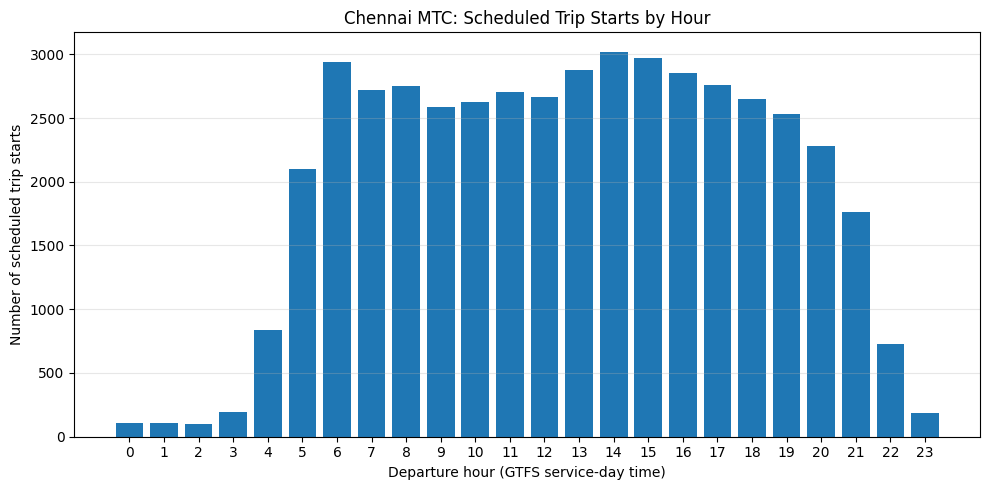

In [12]:
required_time_cols = {"trip_id", "stop_sequence", "departure_time"}
if not required_time_cols.issubset(stop_times.columns):
    raise ValueError(f"stop_times.txt must contain columns: {required_time_cols}")

hourly_data = stop_times[["trip_id", "stop_sequence", "departure_time"]].copy()
hourly_data["stop_sequence_num"] = pd.to_numeric(
    hourly_data["stop_sequence"], errors="coerce"
)
first_departures = (
    hourly_data.dropna(subset=["stop_sequence_num"])
    .sort_values(["trip_id", "stop_sequence_num"])
    .drop_duplicates(subset="trip_id", keep="first")
    .copy()
)
first_departures["departure_time"] = first_departures["departure_time"].astype(str)
first_departures["hour"] = pd.to_numeric(
    first_departures["departure_time"].str.extract(r"^(\d+):")[0],
    errors="coerce"
)
hourly_summary = (
    first_departures.dropna(subset=["hour"])
    .groupby("hour")["trip_id"]
    .nunique()
    .reset_index(name="Scheduled Trip Starts")
)
hourly_summary["hour"] = hourly_summary["hour"].astype(int)
display(hourly_summary)

if not hourly_summary.empty:
    plt.figure(figsize=(10, 5))
    plt.bar(hourly_summary["hour"], hourly_summary["Scheduled Trip Starts"])
    plt.xlabel("Departure hour (GTFS service-day time)")
    plt.ylabel("Number of scheduled trip starts")
    plt.title("Chennai MTC: Scheduled Trip Starts by Hour")
    plt.xticks(hourly_summary["hour"])
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()
else:
    print("No valid first-stop departure times were available for the hourly summary.")


## 11. Daily scheduled trips by service day

The weekly service flags in `calendar.txt` are used to count the trips scheduled for each day of the week. This is a recurring weekly schedule summary. Date-specific exceptions in `calendar_dates.txt` are not applied here, so these figures are not actual operated-trip counts.

,Day,Scheduled Trips
0,Monday,47047
1,Tuesday,47047
2,Wednesday,47047
3,Thursday,47047
4,Friday,47047
5,Saturday,47047
6,Sunday,46973


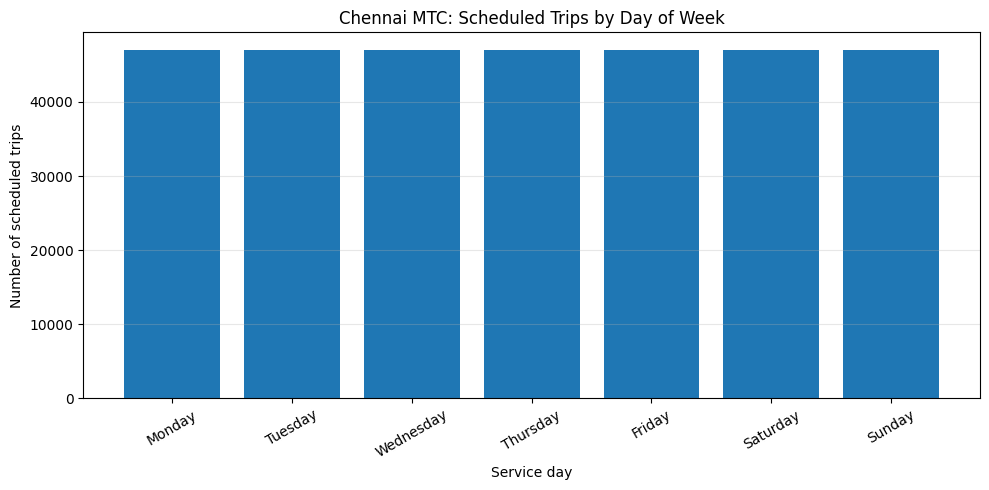

In [13]:
calendar_path = next(GTFS_DIR.rglob("calendar.txt"), None)
days = ["monday", "tuesday", "wednesday", "thursday", "friday", "saturday", "sunday"]

if calendar_path is None:
    print("calendar.txt was not found. Daily scheduled-trip analysis cannot be calculated.")
    daily_summary = pd.DataFrame(columns=["Day", "Scheduled Trips"])
else:
    calendar = pd.read_csv(calendar_path, dtype=str)
    required_calendar_cols = {"service_id", *days}
    if not required_calendar_cols.issubset(calendar.columns):
        raise ValueError(
            "calendar.txt is missing required columns: "
            + str(required_calendar_cols - set(calendar.columns))
        )
    for day in days:
        calendar[day] = pd.to_numeric(calendar[day], errors="coerce").fillna(0)

    if not {"trip_id", "service_id"}.issubset(trips.columns):
        raise ValueError("trips.txt must contain trip_id and service_id columns")

    daily_data = trips[["trip_id", "service_id"]].merge(
        calendar[["service_id"] + days], on="service_id", how="left"
    )
    daily_summary = pd.DataFrame([
        {
            "Day": day.title(),
            "Scheduled Trips": int(
                daily_data.loc[daily_data[day] == 1, "trip_id"].nunique()
            )
        }
        for day in days
    ])
    display(daily_summary)

    plt.figure(figsize=(10, 5))
    plt.bar(daily_summary["Day"], daily_summary["Scheduled Trips"])
    plt.xlabel("Service day")
    plt.ylabel("Number of scheduled trips")
    plt.title("Chennai MTC: Scheduled Trips by Day of Week")
    plt.xticks(rotation=30)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


## 12. Weekday versus weekend schedule comparison

This compares the average scheduled trip count across Monday–Friday with the average across Saturday–Sunday. It is based on `calendar.txt` service flags and does not represent passenger ridership.

,Service Type,Average Scheduled Trips
0,Average weekday,47047.0
1,Average weekend day,47010.0


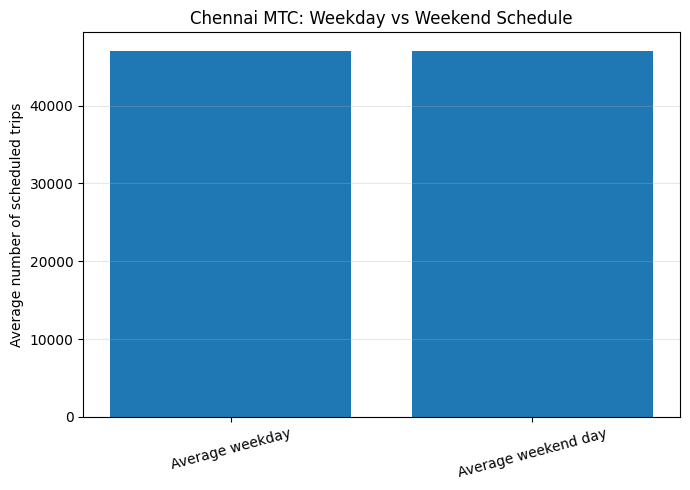

In [14]:
if daily_summary.empty:
    print("Weekday/weekend comparison is unavailable because daily service data is missing.")
else:
    daily_by_day = daily_summary.set_index("Day")["Scheduled Trips"]
    weekday_names = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday"]
    weekend_names = ["Saturday", "Sunday"]
    weekday_values = daily_by_day.reindex(weekday_names).dropna()
    weekend_values = daily_by_day.reindex(weekend_names).dropna()

    weekday_average = weekday_values.mean() if not weekday_values.empty else np.nan
    weekend_average = weekend_values.mean() if not weekend_values.empty else np.nan
    weekday_weekend_comparison = pd.DataFrame({
        "Service Type": ["Average weekday", "Average weekend day"],
        "Average Scheduled Trips": [weekday_average, weekend_average]
    })
    display(weekday_weekend_comparison)

    plt.figure(figsize=(7, 5))
    plt.bar(
        weekday_weekend_comparison["Service Type"],
        weekday_weekend_comparison["Average Scheduled Trips"]
    )
    plt.ylabel("Average number of scheduled trips")
    plt.title("Chennai MTC: Weekday vs Weekend Schedule")
    plt.xticks(rotation=15)
    plt.grid(axis="y", alpha=0.3)
    plt.tight_layout()
    plt.show()


## 13. Visualize the schedule data

The chart shows the routes with the largest number of trip records in the GTFS feed. It describes scheduled service records only, not passenger demand.

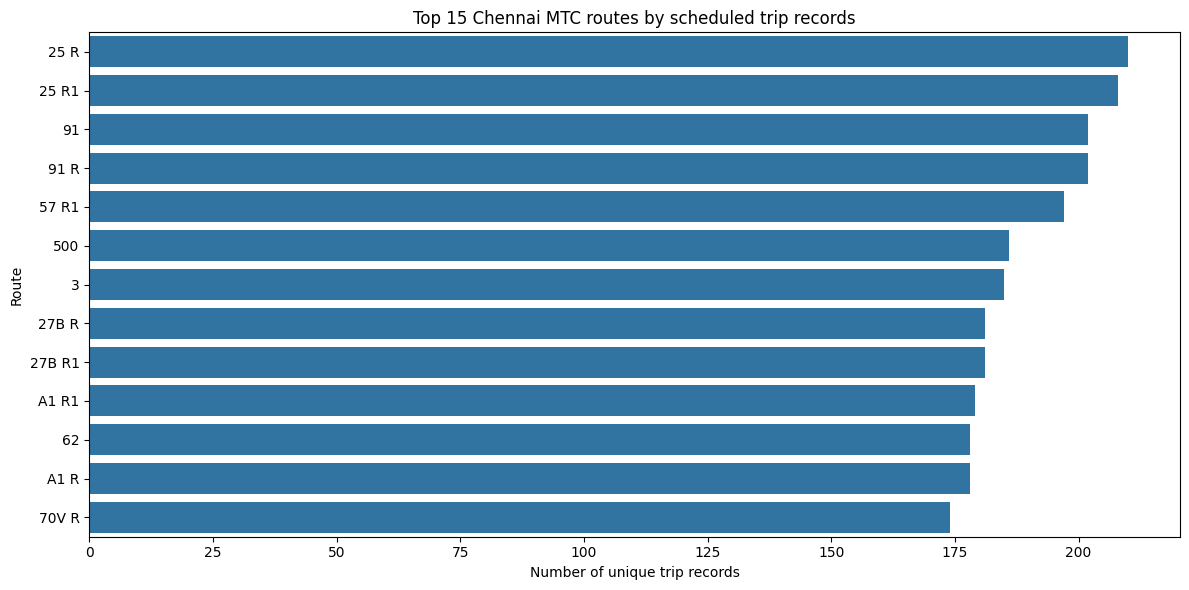

In [15]:
top_routes = route_features.sort_values(
    "scheduled_trip_records", ascending=False
).head(15).copy()

label_col = "route_short_name" if "route_short_name" in top_routes.columns else "route_id"
plt.figure(figsize=(12, 6))
sns.barplot(
    data=top_routes,
    x="scheduled_trip_records",
    y=label_col
)
plt.title("Top 15 Chennai MTC routes by scheduled trip records")
plt.xlabel("Number of unique trip records")
plt.ylabel("Route")
plt.tight_layout()
plt.show()

## 14. Basic stop-time sequence validation

Within each trip, `stop_sequence` should normally define the order of stops. We check whether the column exists and whether repeated sequence values occur within a trip. These checks flag records for review; they do not automatically modify the source data.

In [16]:
if "stop_sequence" in stop_times.columns:
    stop_times["stop_sequence_num"] = pd.to_numeric(
        stop_times["stop_sequence"], errors="coerce"
    )

    duplicate_sequences = stop_times.duplicated(
        subset=["trip_id", "stop_sequence"], keep=False
    ).sum()

    invalid_sequences = stop_times["stop_sequence_num"].isna().sum()

    print("Rows with duplicate trip_id + stop_sequence:", int(duplicate_sequences))
    print("Rows with non-numeric/missing stop_sequence:", int(invalid_sequences))
else:
    print("stop_sequence column is not present in stop_times.txt.")

Rows with duplicate trip_id + stop_sequence: 0
Rows with non-numeric/missing stop_sequence: 0


## 15. Save the initial feature dataset

The generated CSV can be used in the next milestone for data cleaning and exploratory analysis. It is a derived file, so keep the original GTFS source files unchanged.

In [17]:
OUTPUT_DIR = PROJECT_DIR / "data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_file = OUTPUT_DIR / "chennai_route_features_milestone1.csv"
route_features.to_csv(output_file, index=False)

print("Saved route-level features to:", output_file)
print("Saved rows:", len(route_features))

Saved route-level features to: /content/data/processed/chennai_route_features_milestone1.csv
Saved rows: 4611
